Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0    

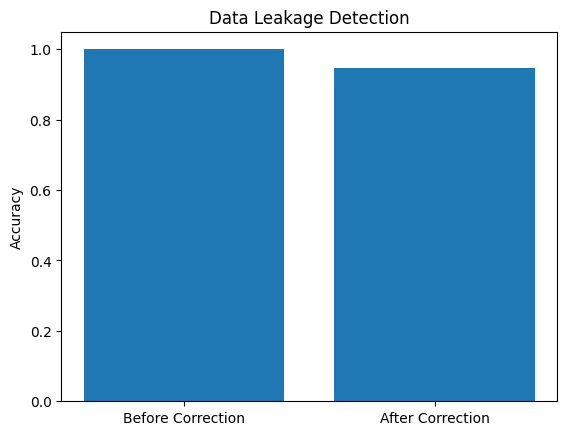

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 1. Load dataset
data = load_breast_cancer(as_frame=True)
df = data.frame

print("Dataset:")
print(df.head())

# 2. Create a leaked feature
df["leaked_feature"] = df["target"]

# 3. Split data into training and testing
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Model BEFORE removing leakage
model1 = DecisionTreeClassifier(random_state=42)
model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)
acc1 = accuracy_score(y_test, pred1)

print("Accuracy before correction:", acc1)

# 5. Remove leaked feature
X = df.drop(["target", "leaked_feature"], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Model AFTER removing leakage
model2 = DecisionTreeClassifier(random_state=42)
model2.fit(X_train, y_train)

pred2 = model2.predict(X_test)
acc2 = accuracy_score(y_test, pred2)

print("Accuracy after correction:", acc2)

# 7. Compare results using graph
plt.bar(
    ["Before Correction", "After Correction"],
    [acc1, acc2]
)

plt.ylabel("Accuracy")
plt.title("Data Leakage Detection")
plt.show()


Original Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimet

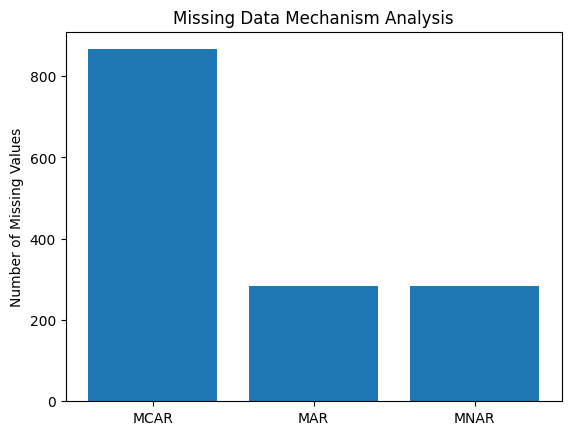

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer(as_frame=True)
df = data.data.copy()

print("Original Dataset:")
print(df.head())

# Create a copy for missing data analysis
mcar = df.copy()
mar = df.copy()
mnar = df.copy()

np.random.seed(42)

# 1. MCAR: Missing Completely At Random
# Values are removed randomly
mask = np.random.rand(*mcar.shape) < 0.05
mcar = mcar.mask(mask)

# 2. MAR: Missing At Random
# Missing values depend on another feature
mar.loc[mar["mean radius"] > mar["mean radius"].median(),
        "mean texture"] = np.nan

# 3. MNAR: Missing Not At Random
# Missing values depend on the value itself
mnar.loc[mnar["mean radius"] > mnar["mean radius"].median(),
         "mean radius"] = np.nan

# Count missing values
print("\nMCAR Missing Values:", mcar.isnull().sum().sum())
print("MAR Missing Values:", mar.isnull().sum().sum())
print("MNAR Missing Values:", mnar.isnull().sum().sum())

# Plot missing values
missing_counts = [
    mcar.isnull().sum().sum(),
    mar.isnull().sum().sum(),
    mnar.isnull().sum().sum()
]

plt.bar(["MCAR", "MAR", "MNAR"], missing_counts)
plt.title("Missing Data Mechanism Analysis")
plt.ylabel("Number of Missing Values")
plt.show()

Dataset loaded successfully!
Dataset shape: (569, 30)

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimensi

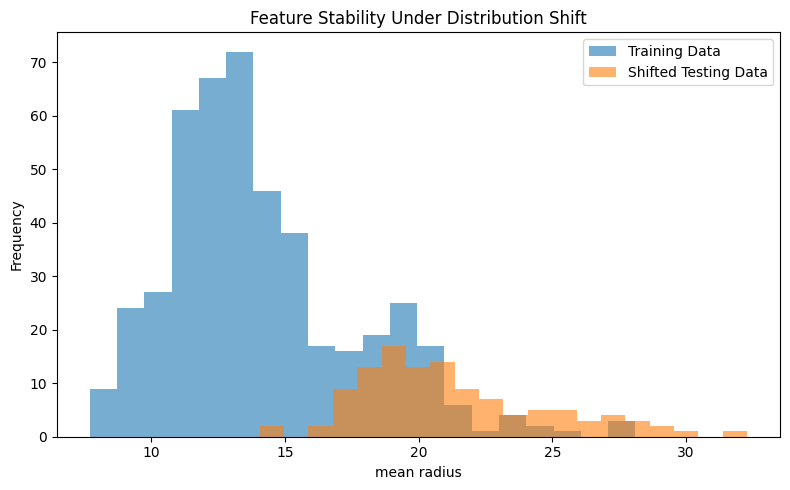

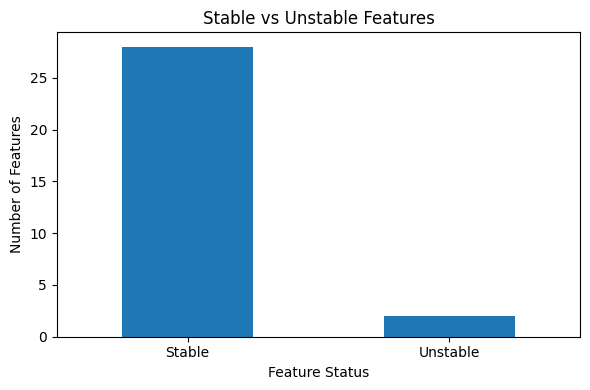


Results saved to feature_stability_results.csv
Project completed successfully!


In [ ]:

# Feature Stability Under Distribution Shift

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from scipy.stats import ks_2samp

# 1. Load dataset
data = load_breast_cancer(as_frame=True)
df = data.data

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# 2. Split dataset
train, test = train_test_split(
    df, test_size=0.2, random_state=42
)

train = train.copy()
test = test.copy()

# 3. Introduce artificial distribution shift
feature = df.columns[0]
test[feature] = test[feature] + 2 * train[feature].std()

print("\nArtificial distribution shift introduced in:", feature)

# 4. Check feature stability
results = []

for col in df.columns:
    p_value = ks_2samp(train[col], test[col]).pvalue

    if p_value < 0.05:
        status = "Unstable"
    else:
        status = "Stable"

    results.append({
        "Feature": col,
        "P-Value": round(p_value, 4),
        "Stability": status
    })

results_df = pd.DataFrame(results)

print("\nFeature Stability Results:")
print(results_df.to_string(index=False))

# 5. Display summary
print("\nStability Summary:")
print(results_df["Stability"].value_counts())

# 6. Plot feature distributions
plt.figure(figsize=(8, 5))

plt.hist(train[feature], bins=20, alpha=0.6,
         label="Training Data")
plt.hist(test[feature], bins=20, alpha=0.6,
         label="Shifted Testing Data")

plt.xlabel(feature)
plt.ylabel("Frequency")
plt.title("Feature Stability Under Distribution Shift")
plt.legend()
plt.tight_layout()
plt.show()

# 7. Plot stable vs unstable feature counts
counts = results_df["Stability"].value_counts()

counts.reindex(["Stable", "Unstable"], fill_value=0).plot(
    kind="bar", figsize=(6, 4)
)

plt.title("Stable vs Unstable Features")
plt.xlabel("Feature Status")
plt.ylabel("Number of Features")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 8. Save results
results_df.to_csv("feature_stability_results.csv", index=False)

print("\nResults saved to feature_stability_results.csv")
print("Project completed successfully!")


Dataset loaded successfully!
Dataset shape: (569, 30)

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dime

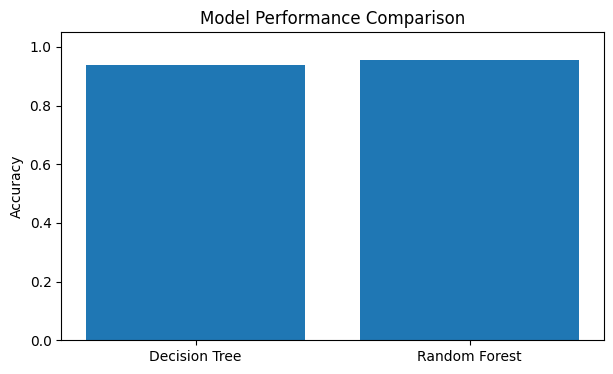

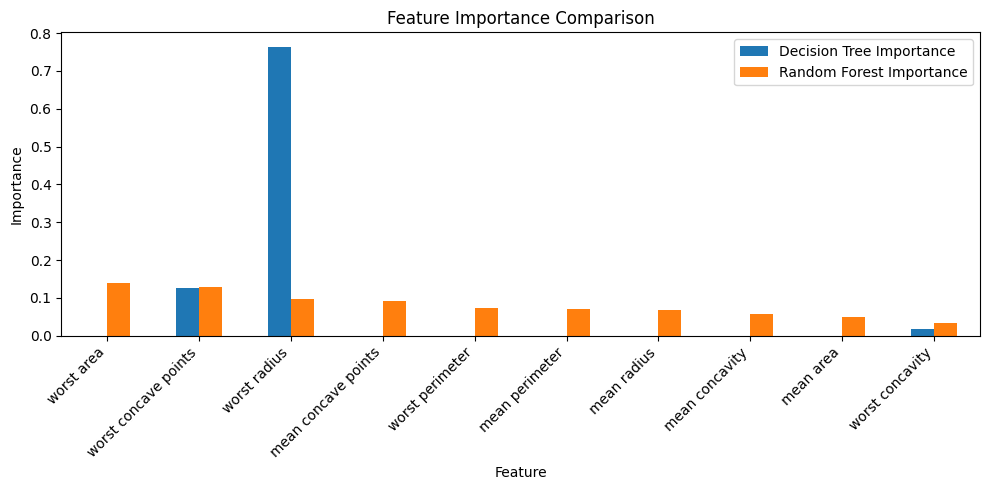


Results saved successfully!
Project completed!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Step 1: Load dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("\nFirst five rows:")
print(X.head())

# Step 2: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Create two models
model1 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Step 4: Train models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

# Step 5: Make predictions
pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)

# Step 6: Compare performance
accuracy1 = accuracy_score(y_test, pred1)
accuracy2 = accuracy_score(y_test, pred2)

f1_1 = f1_score(y_test, pred1)
f1_2 = f1_score(y_test, pred2)

print("\nDecision Tree Results")
print("Accuracy:", round(accuracy1, 4))
print("F1 Score:", round(f1_1, 4))

print("\nRandom Forest Results")
print("Accuracy:", round(accuracy2, 4))
print("F1 Score:", round(f1_2, 4))

# Step 7: Display important features
importance = pd.DataFrame({
    "Feature": X.columns,
    "Decision Tree Importance": model1.feature_importances_,
    "Random Forest Importance": model2.feature_importances_
})

importance = importance.sort_values(
    "Random Forest Importance",
    ascending=False
)

print("\nTop 5 Important Features:")
print(importance.head(5).to_string(index=False))

# Step 8: Plot accuracy comparison
plt.figure(figsize=(7, 4))

plt.bar(
    ["Decision Tree", "Random Forest"],
    [accuracy1, accuracy2]
)

plt.ylabel("Accuracy")
plt.title("Model Performance Comparison")
plt.ylim(0, 1.05)
plt.show()

# Step 9: Plot feature importance
importance.head(10).plot(
    x="Feature",
    y=["Decision Tree Importance",
       "Random Forest Importance"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Feature Importance Comparison")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Step 10: Save results
results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [accuracy1, accuracy2],
    "F1 Score": [f1_1, f1_2]
})

results.to_csv("model_comparison_results.csv", index=False)

print("\nResults saved successfully!")
print("Project completed!")

Dataset loaded successfully!
Dataset shape: (569, 30)
Fold 1 Accuracy: 0.9561
Fold 2 Accuracy: 0.8684
Fold 3 Accuracy: 0.9211
Fold 4 Accuracy: 0.9298
Fold 5 Accuracy: 0.9381

Average Accuracy: 0.9227

Cross-Validation Results:
 Fold  Accuracy
    1  0.956140
    2  0.868421
    3  0.921053
    4  0.929825
    5  0.938053


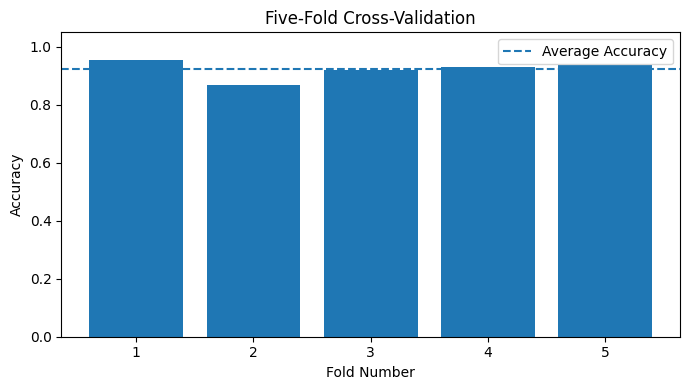


Results saved successfully!
Project completed!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Step 1: Load dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)

# Step 2: Create custom cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 3: Create model
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Step 4: Evaluate each fold
scores = []

for fold, (train_index, test_index) in enumerate(
    cv.split(X, y), start=1
):
    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    scores.append(accuracy)

    print("Fold", fold, "Accuracy:", round(accuracy, 4))

# Step 5: Calculate average accuracy
average_accuracy = sum(scores) / len(scores)

print("\nAverage Accuracy:", round(average_accuracy, 4))

# Step 6: Display results in a table
results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": scores
})

print("\nCross-Validation Results:")
print(results.to_string(index=False))

# Step 7: Plot accuracy
plt.figure(figsize=(7, 4))

plt.bar(results["Fold"], results["Accuracy"])

plt.axhline(
    average_accuracy,
    linestyle="--",
    label="Average Accuracy"
)

plt.xlabel("Fold Number")
plt.ylabel("Accuracy")
plt.title("Five-Fold Cross-Validation")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

# Step 8: Save results
results.to_csv("cross_validation_results.csv", index=False)

print("\nResults saved successfully!")
print("Project completed!")

Dataset loaded successfully!
Dataset shape: (569, 31)

Fairness Evaluation Results:
  Group  Accuracy  Precision  Recall  Samples
Group A     0.963      1.000   0.950       54
Group B     0.917      0.909   0.938       60

Accuracy difference between groups: 0.046


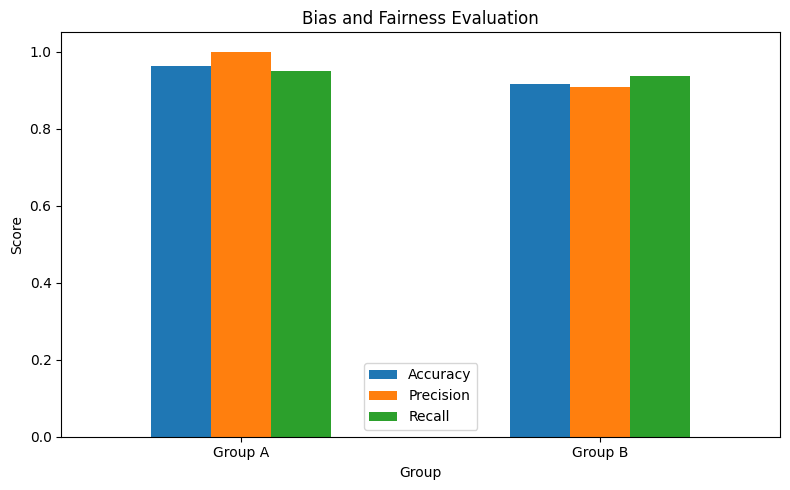


Results saved successfully!
Project completed!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Step 1: Load dataset
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Step 2: Create two artificial groups
df["Group"] = ["Group A" if i % 2 == 0
               else "Group B" for i in range(len(df))]

X = df.drop(columns=["target", "Group"])
y = df["target"]
groups = df["Group"]

# Step 3: Split dataset
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Train model
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

# Step 5: Make predictions
predictions = model.predict(X_test)

# Step 6: Evaluate each group
results = []

for group in ["Group A", "Group B"]:
    mask = (g_test == group)

    actual = y_test[mask]
    predicted = predictions[mask.to_numpy()]

    results.append({
        "Group": group,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "Samples": len(actual)
    })

results_df = pd.DataFrame(results)

print("\nFairness Evaluation Results:")
print(results_df.round(3).to_string(index=False))

# Step 7: Compare accuracy between groups
accuracy_gap = abs(
    results_df.loc[0, "Accuracy"] -
    results_df.loc[1, "Accuracy"]
)

print("\nAccuracy difference between groups:",
      round(accuracy_gap, 3))

# Step 8: Plot accuracy
results_df.plot(
    x="Group",
    y=["Accuracy", "Precision", "Recall"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Bias and Fairness Evaluation")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Step 9: Save results
results_df.to_csv(
    "bias_fairness_results.csv",
    index=False
)

print("\nResults saved successfully!")
print("Project completed!")

Dataset loaded successfully!
Original number of features: 30

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fract

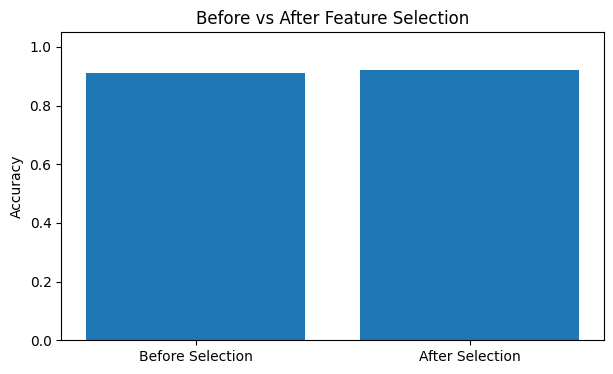

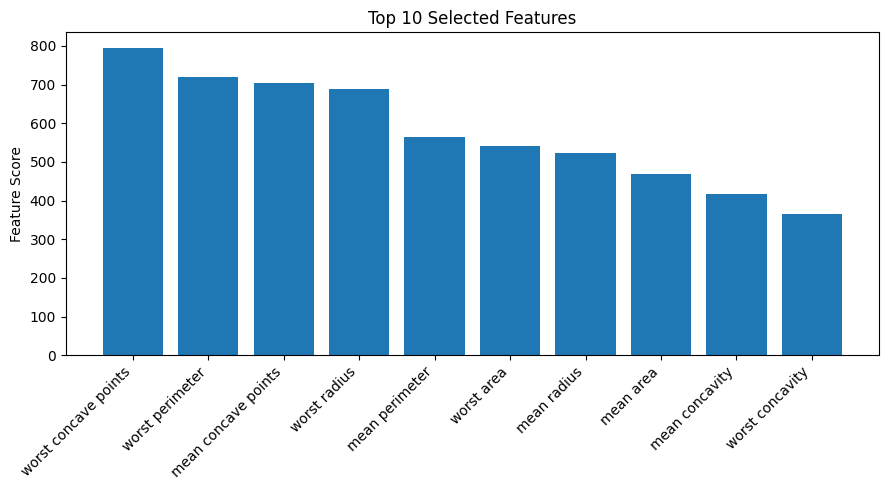


Results saved successfully!
Project completed!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Step 1: Load dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Original number of features:", X.shape[1])
print("\nFirst five rows:")
print(X.head())

# Step 2: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

# Step 3: BEFORE feature selection
model1 = DecisionTreeClassifier(random_state=42)
model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)
acc1 = accuracy_score(y_test, pred1)

print("\nBefore Feature Selection")
print("Number of features:", X_train.shape[1])
print("Accuracy:", round(acc1, 4))

# Step 4: AFTER feature selection
selector = SelectKBest(score_func=f_classif, k=10)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

selected_features = X.columns[selector.get_support()]

print("\nSelected 10 Features:")
print(list(selected_features))

# Step 5: Train model with selected features
model2 = DecisionTreeClassifier(random_state=42)

model2.fit(X_train_selected, y_train)

pred2 = model2.predict(X_test_selected)
acc2 = accuracy_score(y_test, pred2)

print("\nAfter Feature Selection")
print("Number of features:", X_train_selected.shape[1])
print("Accuracy:", round(acc2, 4))

# Step 6: Compare results
results = pd.DataFrame({
    "Model": ["Before Selection", "After Selection"],
    "Features": [30, 10],
    "Accuracy": [acc1, acc2]
})

print("\nPerformance Comparison:")
print(results.to_string(index=False))

# Step 7: Plot accuracy comparison
plt.figure(figsize=(7, 4))

plt.bar(results["Model"], results["Accuracy"])

plt.title("Before vs After Feature Selection")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.show()

# Step 8: Plot selected feature scores
scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).head(10)

plt.figure(figsize=(9, 5))

plt.bar(scores["Feature"], scores["Score"])

plt.title("Top 10 Selected Features")
plt.ylabel("Feature Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Step 9: Save results
results.to_csv("feature_selection_results.csv", index=False)

print("\nResults saved successfully!")
print("Project completed!")


Dataset Shape: (569, 30)

First 5 Records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

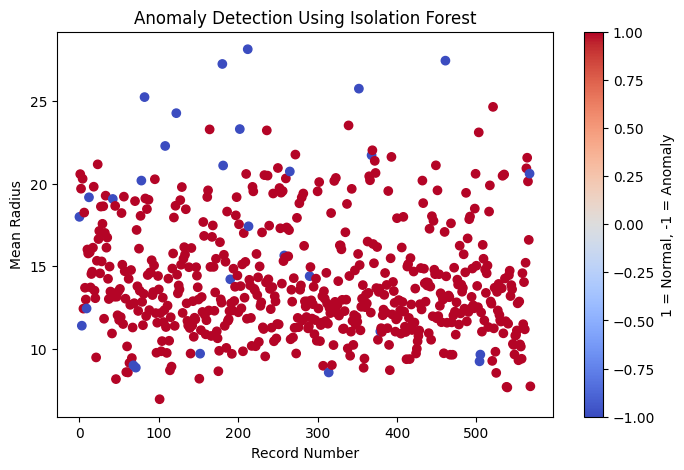


Detected Anomalies:
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0         17.990         10.38          122.80     1001.0          0.11840   
3         11.420         20.38           77.58      386.1          0.14250   
9         12.460         24.04           83.97      475.9          0.11860   
12        19.170         24.80          132.40     1123.0          0.09740   
42        19.070         24.81          128.30     1104.0          0.09081   
68         9.029         17.33           58.79      250.5          0.10660   
71         8.888         14.64           58.79      244.0          0.09783   
78        20.180         23.97          143.70     1245.0          0.12860   
82        25.220         24.91          171.50     1878.0          0.10630   
108       22.270         19.67          152.80     1509.0          0.13260   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
0              0.2776         0.30010      

In [ ]:

# Project 8: Anomaly Detection with No Labels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Step 1: Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)

print("Dataset Shape:", X.shape)
print("\nFirst 5 Records:")
print(X.head())

# Step 2: Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Apply Isolation Forest
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

predictions = model.fit_predict(X_scaled)

# Step 4: Identify normal and abnormal records
# 1 = Normal, -1 = Anomaly

X["Anomaly"] = predictions

X["Status"] = X["Anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

print("\nAnomaly Detection Results:")
print(X[["Anomaly", "Status"]].head(15))

# Step 5: Count normal and abnormal records
normal_count = (predictions == 1).sum()
anomaly_count = (predictions == -1).sum()

print("\nTotal Records:", len(X))
print("Normal Records:", normal_count)
print("Anomalies Detected:", anomaly_count)

# Step 6: Visualize results
plt.figure(figsize=(8, 5))

plt.scatter(
    range(len(X)),
    X["mean radius"],
    c=predictions,
    cmap="coolwarm"
)

plt.xlabel("Record Number")
plt.ylabel("Mean Radius")
plt.title("Anomaly Detection Using Isolation Forest")
plt.colorbar(label="1 = Normal, -1 = Anomaly")
plt.show()

# Step 7: Display detected anomalies
anomalies = X[X["Status"] == "Anomaly"]

print("\nDetected Anomalies:")
print(anomalies.head(10))

# Step 8: Save results
X.to_csv("anomaly_detection_results.csv", index=False)

print("\nResults saved successfully!")


First 5 Records:
        Date      Value
0 2025-01-01  50.993428
1 2025-01-02  50.322638
2 2025-01-03  52.488724
3 2025-01-04  54.823661
4 2025-01-05  51.878785

Model Performance Comparison

Old Model:
MAE: 20.89
RMSE: 22.65

Retrained Model:
MAE: 7.55
RMSE: 8.89


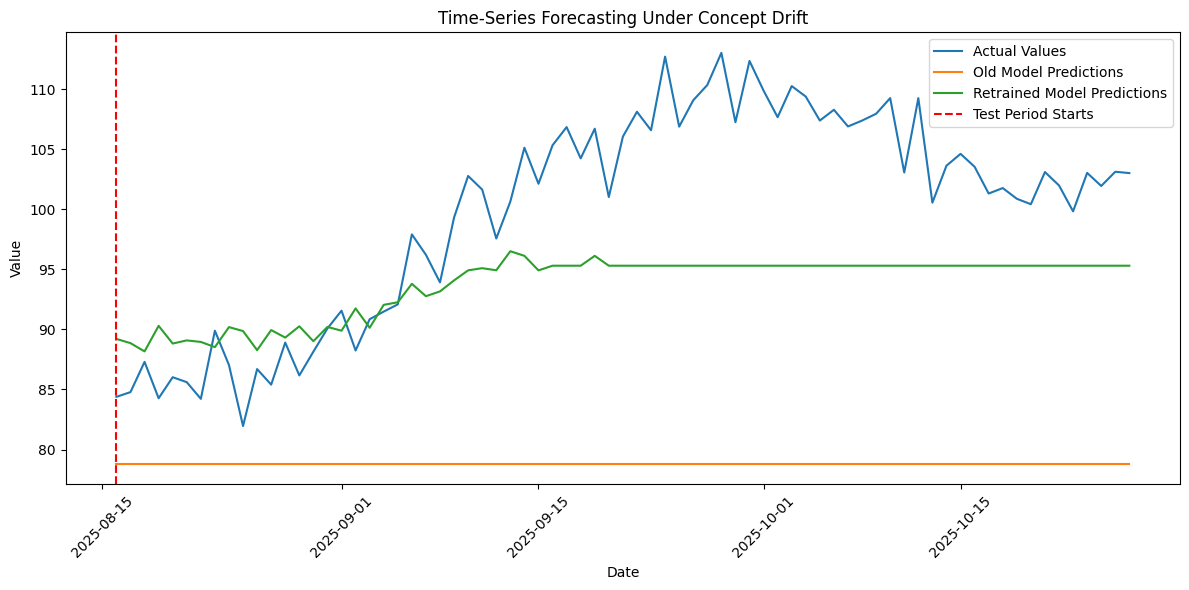


Results saved successfully!


In [ ]:

# Project 9: Time-Series Forecasting Under Concept Drift

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Step 1: Create time-series dataset
np.random.seed(42)

dates = pd.date_range(start="2025-01-01", periods=300, freq="D")

values = []

for i in range(300):
    if i < 180:
        # Old data pattern
        value = 50 + 0.1 * i + 5 * np.sin(i / 10)
    else:
        # New pattern after concept drift
        value = 80 + 0.25 * (i - 180) + 8 * np.sin(i / 10)

    value += np.random.normal(0, 2)
    values.append(value)

df = pd.DataFrame({
    "Date": dates,
    "Value": values
})

print("First 5 Records:")
print(df.head())

# Step 2: Create time-based features
df["Lag_1"] = df["Value"].shift(1)
df["Lag_7"] = df["Value"].shift(7)
df["Rolling_Mean"] = df["Value"].shift(1).rolling(7).mean()

df = df.dropna().reset_index(drop=True)

features = ["Lag_1", "Lag_7", "Rolling_Mean"]

# Step 3: Divide data according to time
old_train = df[df.index < 180]
recent_train = df[(df.index >= 100) & (df.index < 220)]
test = df[df.index >= 220]

X_old = old_train[features]
y_old = old_train["Value"]

X_recent = recent_train[features]
y_recent = recent_train["Value"]

X_test = test[features]
y_test = test["Value"]

# Step 4: Train model on old data
old_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

old_model.fit(X_old, y_old)

old_predictions = old_model.predict(X_test)

# Step 5: Retrain model using recent data
new_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

new_model.fit(X_recent, y_recent)

new_predictions = new_model.predict(X_test)

# Step 6: Compare model performance
old_mae = mean_absolute_error(y_test, old_predictions)
new_mae = mean_absolute_error(y_test, new_predictions)

old_rmse = np.sqrt(mean_squared_error(y_test, old_predictions))
new_rmse = np.sqrt(mean_squared_error(y_test, new_predictions))

print("\nModel Performance Comparison")

print("\nOld Model:")
print("MAE:", round(old_mae, 2))
print("RMSE:", round(old_rmse, 2))

print("\nRetrained Model:")
print("MAE:", round(new_mae, 2))
print("RMSE:", round(new_rmse, 2))

# Step 7: Plot actual and predicted values
plt.figure(figsize=(12, 6))

plt.plot(test["Date"], y_test,
         label="Actual Values")

plt.plot(test["Date"], old_predictions,
         label="Old Model Predictions")

plt.plot(test["Date"], new_predictions,
         label="Retrained Model Predictions")

plt.axvline(
    df.loc[220, "Date"],
    color="red",
    linestyle="--",
    label="Test Period Starts"
)

plt.xlabel("Date")
plt.ylabel("Value")
plt.title("Time-Series Forecasting Under Concept Drift")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 8: Save results
results = pd.DataFrame({
    "Date": test["Date"].values,
    "Actual": y_test.values,
    "Old_Model_Prediction": old_predictions,
    "Retrained_Model_Prediction": new_predictions
})

results.to_csv("concept_drift_results.csv", index=False)

print("\nResults saved successfully!")


In [ ]:

# Project 10: Feature Engineering from Raw Text Logs

import pandas as pd
import re

# Step 1: Create raw text logs
logs = [
    "2026-01-01 10:15:20 INFO User login successful",
    "2026-01-01 10:20:30 ERROR Database connection failed",
    "2026-01-01 10:25:40 WARNING High memory usage",
    "2026-01-02 11:10:15 INFO User logout successful",
    "2026-01-02 11:15:25 ERROR File not found",
    "2026-01-02 11:20:35 INFO User login successful",
    "2026-01-03 12:05:10 WARNING Low disk space",
    "2026-01-03 12:10:20 ERROR Network connection failed",
    "2026-01-03 12:15:30 INFO User logout successful",
    "2026-01-04 13:00:10 INFO User login successful"
]

print("Raw Text Logs:")
for log in logs:
    print(log)

# Step 2: Convert logs into a DataFrame
df = pd.DataFrame({"Raw_Log": logs})

# Step 3: Extract date and time
df["Date"] = df["Raw_Log"].str.extract(
    r"(\d{4}-\d{2}-\d{2})"
)

df["Time"] = df["Raw_Log"].str.extract(
    r"(\d{2}:\d{2}:\d{2})"
)

# Step 4: Extract log level
df["Log_Level"] = df["Raw_Log"].str.extract(
    r"\d{2}:\d{2}:\d{2}\s+(\w+)"
)

# Step 5: Extract message
df["Message"] = df["Raw_Log"].str.extract(
    r"\d{2}:\d{2}:\d{2}\s+\w+\s+(.*)"
)

# Step 6: Create numerical features
df["Message_Length"] = df["Message"].str.len()

df["Word_Count"] = df["Message"].str.split().str.len()

df["Is_Error"] = (
    df["Log_Level"] == "ERROR"
).astype(int)

df["Is_Warning"] = (
    df["Log_Level"] == "WARNING"
).astype(int)

df["Is_Login"] = (
    df["Message"].str.contains("login", case=False)
).astype(int)

df["Is_Failed"] = (
    df["Message"].str.contains(
        "failed|not found", case=False
    )
).astype(int)

# Step 7: Display extracted features
print("\nExtracted Features:")
print(df)

# Step 8: Count different log types
print("\nLog Level Counts:")
print(df["Log_Level"].value_counts())

print("\nTotal Errors:", df["Is_Error"].sum())
print("Total Warnings:", df["Is_Warning"].sum())
print("Total Login Events:", df["Is_Login"].sum())
print("Total Failed Events:", df["Is_Failed"].sum())

# Step 9: Save the results
df.to_csv("text_log_features.csv", index=False)

print("\nFeature engineering completed!")
print("Results saved successfully!")


Raw Text Logs:
2026-01-01 10:15:20 INFO User login successful
2026-01-01 10:20:30 ERROR Database connection failed
2026-01-01 10:25:40 WARNING High memory usage
2026-01-02 11:10:15 INFO User logout successful
2026-01-02 11:15:25 ERROR File not found
2026-01-02 11:20:35 INFO User login successful
2026-01-03 12:05:10 WARNING Low disk space
2026-01-03 12:10:20 ERROR Network connection failed
2026-01-03 12:15:30 INFO User logout successful
2026-01-04 13:00:10 INFO User login successful

Extracted Features:
                                             Raw_Log        Date      Time  \
0     2026-01-01 10:15:20 INFO User login successful  2026-01-01  10:15:20   
1  2026-01-01 10:20:30 ERROR Database connection ...  2026-01-01  10:20:30   
2      2026-01-01 10:25:40 WARNING High memory usage  2026-01-01  10:25:40   
3    2026-01-02 11:10:15 INFO User logout successful  2026-01-02  11:10:15   
4           2026-01-02 11:15:25 ERROR File not found  2026-01-02  11:15:25   
5     2026-01-02 11:20:3

Dataset Shape: (569, 30)

Grid Search Best Parameters:
{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 150}

Random Search Best Parameters:
{'n_estimators': 150, 'min_samples_split': 5, 'max_depth': None}

Performance Comparison:
   Search Method  Accuracy  Time (Seconds)
0    Grid Search  0.947368       18.476376
1  Random Search  0.947368        3.288746


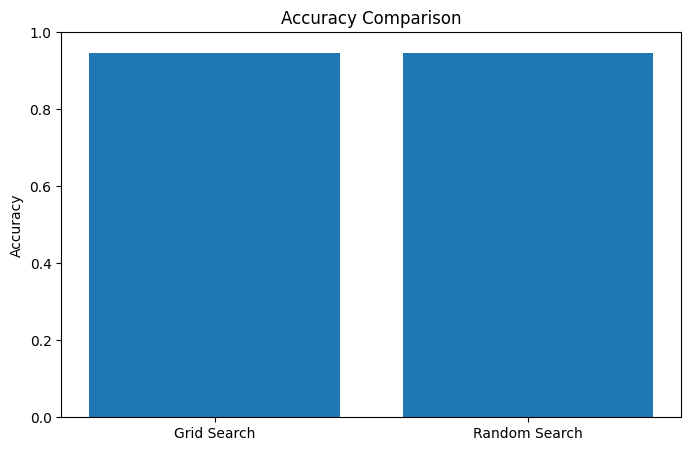

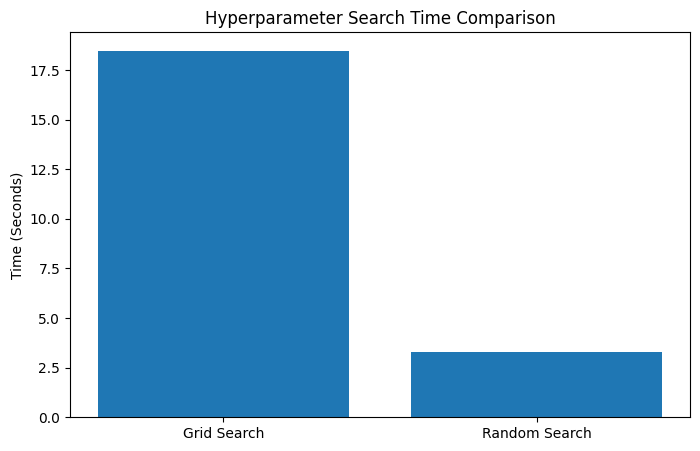


Results saved successfully!


In [ ]:

# Project 11: Hyperparameter Search Efficiency

import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Step 1: Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)

# Step 2: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Define model
model = RandomForestClassifier(random_state=42)

# Step 4: Define hyperparameter combinations
param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

# Step 5: Apply Grid Search
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

grid_search.fit(X_train, y_train)

grid_time = time.time() - start_time

grid_predictions = grid_search.best_estimator_.predict(X_test)

grid_accuracy = accuracy_score(
    y_test, grid_predictions
)

# Step 6: Apply Random Search
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=5,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

random_search.fit(X_train, y_train)

random_time = time.time() - start_time

random_predictions = random_search.best_estimator_.predict(X_test)

random_accuracy = accuracy_score(
    y_test, random_predictions
)

# Step 7: Display best hyperparameters
print("\nGrid Search Best Parameters:")
print(grid_search.best_params_)

print("\nRandom Search Best Parameters:")
print(random_search.best_params_)

# Step 8: Compare results
results = pd.DataFrame({
    "Search Method": ["Grid Search", "Random Search"],
    "Accuracy": [grid_accuracy, random_accuracy],
    "Time (Seconds)": [grid_time, random_time]
})

print("\nPerformance Comparison:")
print(results)

# Step 9: Plot accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(
    results["Search Method"],
    results["Accuracy"]
)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

# Step 10: Plot time comparison
plt.figure(figsize=(8, 5))

plt.bar(
    results["Search Method"],
    results["Time (Seconds)"]
)

plt.title("Hyperparameter Search Time Comparison")
plt.ylabel("Time (Seconds)")
plt.show()

# Step 11: Save results
results.to_csv(
    "hyperparameter_search_results.csv",
    index=False
)

print("\nResults saved successfully!")



Dataset Shape: (569, 30)

Model Performance:
    Data Type  Accuracy
0  Clean Data  0.956140
1  Noisy Data  0.868421

Clean Data Accuracy: 0.9561
Noisy Data Accuracy: 0.8684

Accuracy Difference: 0.0877


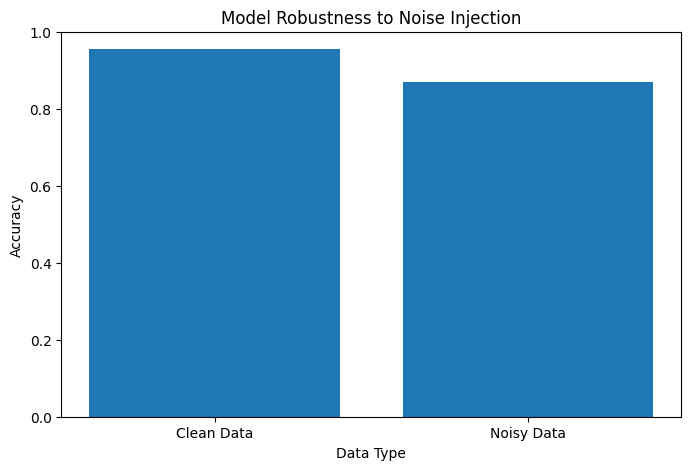


Results saved successfully!


In [ ]:

# Project 12: Model Robustness to Noise Injection

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Step 1: Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)

# Step 2: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Train model on clean training data
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Step 4: Test on clean data
clean_predictions = model.predict(X_test)

clean_accuracy = accuracy_score(
    y_test, clean_predictions
)

# Step 5: Add noise to test data
np.random.seed(42)

noise = np.random.normal(
    loc=0,
    scale=0.5,
    size=X_test.shape
)

X_test_noisy = X_test + noise

# Step 6: Test model on noisy data
noisy_predictions = model.predict(X_test_noisy)

noisy_accuracy = accuracy_score(
    y_test, noisy_predictions
)

# Step 7: Compare accuracy
results = pd.DataFrame({
    "Data Type": ["Clean Data", "Noisy Data"],
    "Accuracy": [clean_accuracy, noisy_accuracy]
})

print("\nModel Performance:")
print(results)

print("\nClean Data Accuracy:",
      round(clean_accuracy, 4))

print("Noisy Data Accuracy:",
      round(noisy_accuracy, 4))

# Step 8: Calculate accuracy difference
difference = clean_accuracy - noisy_accuracy

print("\nAccuracy Difference:",
      round(difference, 4))

# Step 9: Plot accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(
    results["Data Type"],
    results["Accuracy"]
)

plt.title("Model Robustness to Noise Injection")
plt.xlabel("Data Type")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

# Step 10: Save results
results.to_csv(
    "noise_robustness_results.csv",
    index=False
)

print("\nResults saved successfully!")


Dataset Shape: (569, 30)

Model Accuracy Comparison:
                 Model  Accuracy
0        Decision Tree  0.938596
1        Random Forest  0.956140
2  Logistic Regression  0.982456
3      Voting Ensemble  0.973684

Prediction Diversity: 5.26 %


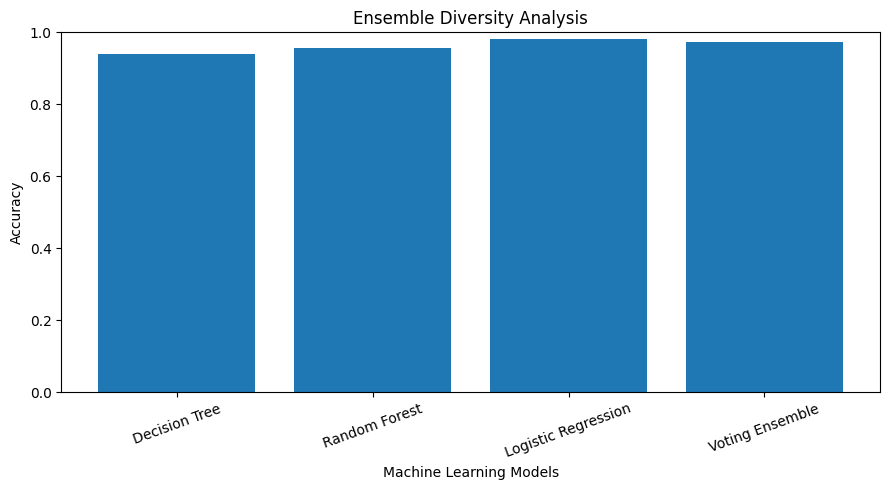


Results saved successfully!


In [ ]:

# Project 13: Ensemble Diversity Analysis

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

# Step 1: Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)

# Step 2: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Create three different models
model1 = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model3 = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Step 4: Train individual models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

# Step 5: Make predictions
pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)
pred3 = model3.predict(X_test)

# Step 6: Calculate individual accuracy
acc1 = accuracy_score(y_test, pred1)
acc2 = accuracy_score(y_test, pred2)
acc3 = accuracy_score(y_test, pred3)

# Step 7: Calculate prediction diversity
different_predictions = (
    (pred1 != pred2).sum()
    + (pred1 != pred3).sum()
    + (pred2 != pred3).sum()
)

total_comparisons = len(y_test) * 3

diversity = (
    different_predictions / total_comparisons
) * 100

# Step 8: Create Voting Classifier
ensemble = VotingClassifier(
    estimators=[
        ("decision_tree", model1),
        ("random_forest", model2),
        ("logistic_regression", model3)
    ],
    voting="hard"
)

ensemble.fit(X_train, y_train)

ensemble_predictions = ensemble.predict(X_test)

ensemble_accuracy = accuracy_score(
    y_test, ensemble_predictions
)

# Step 9: Display results
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "Voting Ensemble"
    ],
    "Accuracy": [
        acc1,
        acc2,
        acc3,
        ensemble_accuracy
    ]
})

print("\nModel Accuracy Comparison:")
print(results)

print("\nPrediction Diversity:",
      round(diversity, 2), "%")

# Step 10: Plot accuracy comparison
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.title("Ensemble Diversity Analysis")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Step 11: Save results
results.to_csv(
    "ensemble_diversity_results.csv",
    index=False
)

print("\nResults saved successfully!")


In [ ]:

# Project 15: Streaming Data Simulation Lab

import pandas as pd
from sklearn.datasets import load_breast_cancer

# Step 1: Load the dataset
data = load_breast_cancer(as_frame=True)
df = data.frame

# Step 2: Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Step 3: Set batch size
batch_size = 50

# Step 4: Process data in small batches
batch_number = 1

for start in range(0, len(df), batch_size):

    # Get one batch of data
    batch = df.iloc[start:start + batch_size]

    # Count Benign and Malignant cases
    malignant = (batch['target'] == 0).sum()
    benign = (batch['target'] == 1).sum()

    # Display batch results
    print("Batch Number:", batch_number)
    print("Total Records:", len(batch))
    print("Benign Cases:", benign)
    print("Malignant Cases:", malignant)
    print("--------------------------")

    batch_number += 1

# Step 5: Display final results
print("STREAMING COMPLETED")
print("Total Records:", len(df))
print("Total Benign Cases:", (df['target'] == 1).sum())
print("Total Malignant Cases:", (df['target'] == 0).sum())


Batch Number: 1
Total Records: 50
Benign Cases: 35
Malignant Cases: 15
--------------------------
Batch Number: 2
Total Records: 50
Benign Cases: 28
Malignant Cases: 22
--------------------------
Batch Number: 3
Total Records: 50
Benign Cases: 29
Malignant Cases: 21
--------------------------
Batch Number: 4
Total Records: 50
Benign Cases: 37
Malignant Cases: 13
--------------------------
Batch Number: 5
Total Records: 50
Benign Cases: 33
Malignant Cases: 17
--------------------------
Batch Number: 6
Total Records: 50
Benign Cases: 35
Malignant Cases: 15
--------------------------
Batch Number: 7
Total Records: 50
Benign Cases: 26
Malignant Cases: 24
--------------------------
Batch Number: 8
Total Records: 50
Benign Cases: 36
Malignant Cases: 14
--------------------------
Batch Number: 9
Total Records: 50
Benign Cases: 28
Malignant Cases: 22
--------------------------
Batch Number: 10
Total Records: 50
Benign Cases: 26
Malignant Cases: 24
--------------------------
Batch Number: 11
To